# Compact benchmark comparison

Comparison of Exhaustive, Greedy, Heuristic, Uniform, and Random on the compact one- and two-dimensional datasets. All errors use exact sequential $P/Q$ outcome probabilities.

In [36]:
# Resolve the project whether Jupyter starts here or from the repository root.
import importlib
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working = Path.cwd().resolve()
PROJECT = working / "problem-2-min-error-seq" if (working / "problem-2-min-error-seq").is_dir() else working
SOURCE = PROJECT / "src"
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

_analysis_module = importlib.reload(importlib.import_module("analysis"))
run_analysis = _analysis_module.run_analysis
_figures_module = importlib.reload(importlib.import_module("figures"))
summary_markdown = _figures_module.summary_markdown
allocation_match_table = _figures_module.allocation_match_table
allocation_match_markdown = _figures_module.allocation_match_markdown
load_summary = _figures_module.load_summary
load_case_rows = _figures_module.load_case_rows


## Settings

Test mode uses 90 balanced cases per dimension. Full mode uses all compact cases with $K,M\in\{3,4\}$. Saved results are loaded by default; `RUN_ANALYSIS` controls algorithm execution.

In [37]:
# Load saved results by default. Set this to True to run or resume the study.
RUN_ANALYSIS = False

# Use "full" for the complete study after confirming the test run.
RUN_MODE = "full"
RESUME = True
TIME_LIMIT_SECONDS = 30.0
EXACT_K_MAX = 4

# These controls apply only to the heuristic method.
BEAM_WIDTH = 3
MAX_ITERATIONS = 30

# This notebook is intentionally tied to the compact datasets.
STUDY = "compact"

## Results

Matched method results with checkpoint support.

In [38]:
# Load saved tables unless an algorithm run is explicitly requested.
if RUN_ANALYSIS:
    run_analysis = importlib.reload(importlib.import_module("analysis")).run_analysis
    analysis = run_analysis(
        project=PROJECT,
        study=STUDY,
        mode=RUN_MODE,
        resume=RESUME,
        exact_k_max=EXACT_K_MAX,
        time_limit=TIME_LIMIT_SECONDS,
        beam_width=BEAM_WIDTH,
        max_iterations=MAX_ITERATIONS,
    )
    print("Analysis run requested; algorithms were run or resumed.")
else:
    result_output = PROJECT / "results" / STUDY / RUN_MODE
    try:
        saved_summary = load_summary(PROJECT, STUDY, mode=RUN_MODE)
        saved_rows = load_case_rows(PROJECT, STUDY, mode=RUN_MODE)
    except FileNotFoundError as error:
        raise FileNotFoundError(
            f"Saved {STUDY} {RUN_MODE} results are unavailable. "
            "Set RUN_ANALYSIS = True to generate them."
        ) from error
    analysis = {
        "summary": saved_summary,
        "rows": saved_rows,
        "output": result_output,
    }
    print("Loaded saved results; no allocation algorithms were run.")

# Confirm that this notebook used both compact datasets and all five methods.
expected_datasets = {"compact_benchmark_1d", "compact_benchmark_2d"}
expected_methods = {"Exhaustive", "Greedy", "Heuristic", "Uniform", "Random"}
observed_datasets = {row["dataset"] for row in analysis["rows"]}
observed_methods = {row["method"] for row in analysis["rows"]}
assert observed_datasets == expected_datasets
assert observed_methods == expected_methods
assert {int(row["K"]) for row in analysis["rows"]} == {3, 4}
assert {int(row["M"]) for row in analysis["rows"]} == {3, 4}

case_counts = {
    dimension: len({
        (row["dataset"], row["case"])
        for row in analysis["rows"]
        if int(row["dimension"]) == dimension
    })
    for dimension in (1, 2)
}
if RUN_MODE == "test":
    assert case_counts == {1: 90, 2: 90}

print("Verified datasets:", sorted(observed_datasets))
print("Verified methods:", sorted(observed_methods))
print("Unique cases by dimension:", case_counts)
print("Results directory:", analysis["output"])

Loaded saved results; no allocation algorithms were run.
Verified datasets: ['compact_benchmark_1d', 'compact_benchmark_2d']
Verified methods: ['Exhaustive', 'Greedy', 'Heuristic', 'Random', 'Uniform']
Unique cases by dimension: {1: 600, 2: 600}
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-2-min-error-seq/results/compact/full


## Completion summary

Method status counts and matched error summaries.

In [39]:
# Report method completion before displaying aggregate values.
from collections import Counter

completion = Counter((row["method"], row["status"]) for row in analysis["rows"])
print("Method-status counts:", completion)
display(Markdown(summary_markdown(analysis["summary"])))

Method-status counts: Counter({('Exhaustive', 'ok'): 4740, ('Greedy', 'ok'): 4740, ('Heuristic', 'ok'): 4740, ('Uniform', 'ok'): 4740, ('Random', 'ok'): 4740})


| Dimension | Budget | Method | Cases | Mean Error Probability | Mean Time (s) | Mean Gap |
|---|---:|---|---:|---:|---:|---:|
| One-dimensional | 1 | Exhaustive | 600 | 0.32679 | 0.0505 | 0.00000 |
| One-dimensional | 1 | Greedy | 600 | 0.44214 | 0.0002 | 0.11535 |
| One-dimensional | 1 | Heuristic | 600 | 0.33404 | 0.0008 | 0.00725 |
| One-dimensional | 1 | Random | 600 | 0.62310 | 0.0001 | 0.29632 |
| One-dimensional | 1 | Uniform | 600 | 0.61613 | 0.0002 | 0.28934 |
| One-dimensional | 2 | Exhaustive | 600 | 0.16847 | 0.2988 | 0.00000 |
| One-dimensional | 2 | Greedy | 600 | 0.34659 | 0.0003 | 0.17812 |
| One-dimensional | 2 | Heuristic | 600 | 0.18229 | 0.0010 | 0.01382 |
| One-dimensional | 2 | Random | 600 | 0.54920 | 0.0001 | 0.38073 |
| One-dimensional | 2 | Uniform | 600 | 0.53316 | 0.0002 | 0.36468 |
| One-dimensional | 3 | Exhaustive | 594 | 0.08411 | 0.9200 | 0.00000 |
| One-dimensional | 3 | Greedy | 594 | 0.26227 | 0.0004 | 0.17816 |
| One-dimensional | 3 | Heuristic | 594 | 0.09715 | 0.0012 | 0.01303 |
| One-dimensional | 3 | Random | 594 | 0.47988 | 0.0001 | 0.39577 |
| One-dimensional | 3 | Uniform | 594 | 0.46393 | 0.0002 | 0.37982 |
| One-dimensional | 4 | Exhaustive | 573 | 0.05167 | 1.9859 | 0.00000 |
| One-dimensional | 4 | Greedy | 573 | 0.21020 | 0.0005 | 0.15853 |
| One-dimensional | 4 | Heuristic | 573 | 0.05830 | 0.0014 | 0.00663 |
| One-dimensional | 4 | Random | 573 | 0.43221 | 0.0001 | 0.38054 |
| One-dimensional | 4 | Uniform | 573 | 0.41392 | 0.0002 | 0.36226 |
| Two-dimensional | 1 | Exhaustive | 600 | 0.36134 | 0.0628 | 0.00000 |
| Two-dimensional | 1 | Greedy | 600 | 0.44936 | 0.0003 | 0.08802 |
| Two-dimensional | 1 | Heuristic | 600 | 0.36905 | 0.0009 | 0.00771 |
| Two-dimensional | 1 | Random | 600 | 0.63200 | 0.0002 | 0.27066 |
| Two-dimensional | 1 | Uniform | 600 | 0.62653 | 0.0002 | 0.26519 |
| Two-dimensional | 2 | Exhaustive | 600 | 0.20900 | 0.3176 | 0.00000 |
| Two-dimensional | 2 | Greedy | 600 | 0.35573 | 0.0004 | 0.14673 |
| Two-dimensional | 2 | Heuristic | 600 | 0.22368 | 0.0011 | 0.01469 |
| Two-dimensional | 2 | Random | 600 | 0.57344 | 0.0002 | 0.36444 |
| Two-dimensional | 2 | Uniform | 600 | 0.56019 | 0.0002 | 0.35120 |
| Two-dimensional | 3 | Exhaustive | 597 | 0.12389 | 1.0054 | 0.00000 |
| Two-dimensional | 3 | Greedy | 597 | 0.28060 | 0.0005 | 0.15671 |
| Two-dimensional | 3 | Heuristic | 597 | 0.13806 | 0.0013 | 0.01417 |
| Two-dimensional | 3 | Random | 597 | 0.51671 | 0.0002 | 0.39282 |
| Two-dimensional | 3 | Uniform | 597 | 0.49608 | 0.0002 | 0.37219 |
| Two-dimensional | 4 | Exhaustive | 576 | 0.08594 | 2.2616 | 0.00000 |
| Two-dimensional | 4 | Greedy | 576 | 0.23008 | 0.0005 | 0.14413 |
| Two-dimensional | 4 | Heuristic | 576 | 0.09503 | 0.0015 | 0.00908 |
| Two-dimensional | 4 | Random | 576 | 0.47047 | 0.0002 | 0.38453 |
| Two-dimensional | 4 | Uniform | 576 | 0.44080 | 0.0002 | 0.35485 |

## Mean runtime

Mean runtime by dimension, $K$, and method for completed matched evaluations.

In [40]:
from collections import defaultdict
from statistics import fmean

def mean_runtime_table(rows):
    matched = _figures_module._matched_rows(rows)
    methods = [
        method for method in _figures_module.STYLES
        if any(row["method"] == method for row in matched)
    ]
    grouped = defaultdict(list)
    for row in matched:
        grouped[(int(row["dimension"]), int(row["K"]), row["method"])].append(
            float(row["seconds"])
        )

    table = []
    for dimension in (1, 2):
        K_values = sorted({
            int(row["K"]) for row in matched
            if int(row["dimension"]) == dimension
        })
        for K in K_values:
            row = {"dimension": dimension, "K": K}
            counts = []
            for method in methods:
                values = grouped[(dimension, K, method)]
                row[f"{method.lower()}_mean_seconds"] = fmean(values)
                counts.append(len(values))
            if len(set(counts)) != 1:
                raise RuntimeError(
                    f"Runtime comparison is not matched for dimension={dimension}, K={K}"
                )
            row["runs_per_method"] = counts[0]
            table.append(row)
    return table, methods


def runtime_markdown(rows, methods):
    headings = ["Dimension", "K", "Runs per method", *methods]
    lines = [
        "| " + " | ".join(headings) + " |",
        "|" + "|".join("---:" for _ in headings) + "|",
    ]
    for row in rows:
        values = [f"{row['dimension']}D", str(row["K"]), str(row["runs_per_method"])]
        values.extend(
            f"{row[f'{method.lower()}_mean_seconds']:.5f}"
            for method in methods
        )
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)


runtime_rows, runtime_methods = mean_runtime_table(analysis["rows"])
_analysis_module.write_csv(
    analysis["output"] / "tables" / "mean_runtime.csv",
    runtime_rows,
)
display(Markdown(runtime_markdown(runtime_rows, runtime_methods)))

| Dimension | K | Runs per method | Exhaustive | Greedy | Heuristic | Uniform | Random |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 1D | 3 | 1168 | 0.03162 | 0.00023 | 0.00061 | 0.00010 | 0.00010 |
| 1D | 4 | 1199 | 1.54889 | 0.00049 | 0.00150 | 0.00020 | 0.00019 |
| 2D | 3 | 1173 | 0.03687 | 0.00025 | 0.00066 | 0.00011 | 0.00010 |
| 2D | 4 | 1200 | 1.73997 | 0.00056 | 0.00168 | 0.00023 | 0.00022 |

## Allocation and error results

Allocation agreement, mean error by budget fraction, and field-family error with instance-level 95% confidence intervals.

### Allocation Match Statistics

| Dimension | K | Comparison | Matches | Runs | Match (%) | 95% CI |
|---|---:|---|---:|---:|---:|---:|
| One-dimensional | 3 | Greedy–Heuristic | 126 | 1168 | 10.8 | [9.0, 12.6] |
| One-dimensional | 3 | Greedy–Exhaustive | 124 | 1168 | 10.6 | [8.8, 12.4] |
| One-dimensional | 4 | Greedy–Heuristic | 35 | 1199 | 2.9 | [2.0, 3.9] |
| One-dimensional | 4 | Greedy–Exhaustive | 37 | 1199 | 3.1 | [2.1, 4.1] |
| Two-dimensional | 3 | Greedy–Heuristic | 203 | 1173 | 17.3 | [15.1, 19.5] |
| Two-dimensional | 3 | Greedy–Exhaustive | 211 | 1173 | 18.0 | [15.8, 20.2] |
| Two-dimensional | 4 | Greedy–Heuristic | 111 | 1200 | 9.2 | [7.6, 10.9] |
| Two-dimensional | 4 | Greedy–Exhaustive | 135 | 1200 | 11.2 | [9.5, 13.0] |

### Error Probability

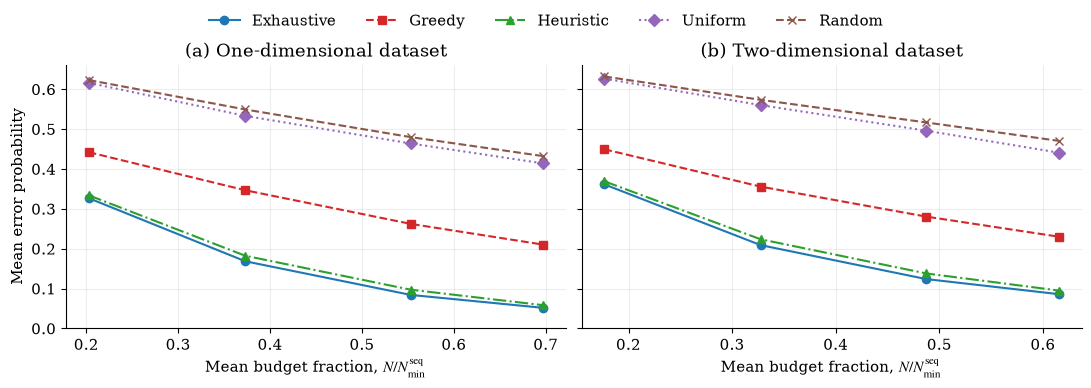

### Error By Field Family

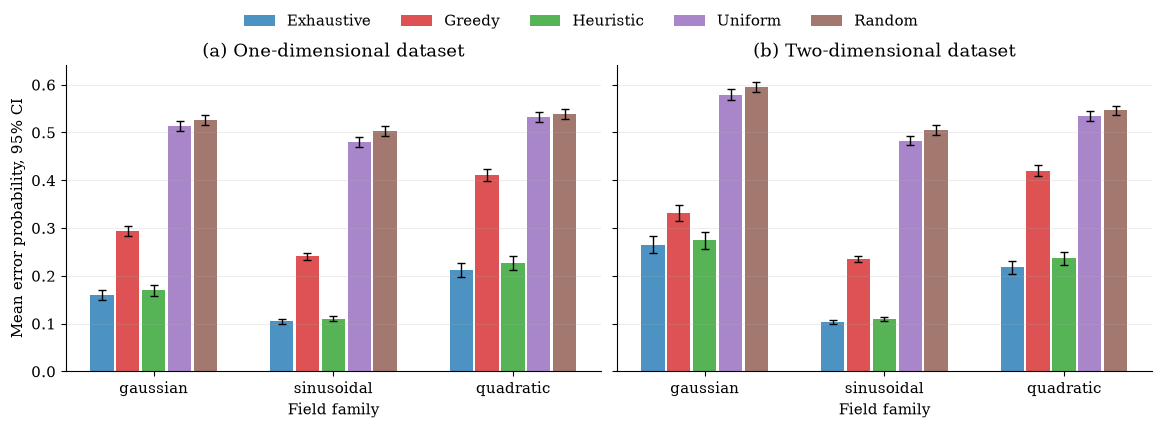

In [41]:
# Save and display the requested figures. Runtime is table-only.
from collections import defaultdict
from statistics import fmean
_figures_module = importlib.reload(importlib.import_module("figures"))


def instance_averaged_error_rows(rows):
    grouped = defaultdict(list)
    metadata = {}
    for row in _figures_module._matched_rows(rows):
        key = (row["dataset"], row["case"], row["method"])
        grouped[key].append(_figures_module._error(row))
        metadata[key] = row

    averaged = []
    for key, values in grouped.items():
        row = dict(metadata[key])
        mean_error = fmean(values)
        row["N"] = 0
        row["actual_error"] = mean_error
        row["error_probability"] = mean_error
        averaged.append(row)
    return averaged

if not analysis["summary"]:
    raise RuntimeError("No matched completed cases are available for plotting")

allocation_stats = _figures_module.allocation_match_table(analysis["rows"])
_analysis_module.write_csv(
    analysis["output"] / "tables" / "allocation_match.csv",
    allocation_stats,
)
display(Markdown("### Allocation Match Statistics"))
display(Markdown(_figures_module.allocation_match_markdown(allocation_stats)))

figures = {
    "error_probability": _figures_module.plot_mean_error(analysis["summary"]),
    "error_by_field_family": _figures_module.plot_error_by_family(
        instance_averaged_error_rows(analysis["rows"])
    ),
}
figure_directory = analysis["output"] / "figures"
figure_directory.mkdir(parents=True, exist_ok=True)
for obsolete_name in ("runtime_by_k", "runtime_boxplot", "seconds"):
    for extension in ("pdf", "png"):
        (figure_directory / f"{obsolete_name}.{extension}").unlink(missing_ok=True)
for name, figure in figures.items():
    for extension in ("pdf", "png"):
        figure.savefig(
            figure_directory / f"{name}.{extension}",
            dpi=300,
            bbox_inches="tight",
        )
    display(Markdown(f"### {name.replace('_', ' ').title()}"))
    display(figure)
    plt.close(figure)
